# Baseline Ingênuo — Classe Majoritária

Este notebook tem como objetivo estabelecer um modelo de referência (*baseline*) para o problema de classificação do resultado de partidas de *League of Legends*.

Será utilizado o método da **classe majoritária**, que consiste em identificar a classe mais frequente no conjunto de treinamento e utilizá-la como previsão para todas as partidas dos conjuntos de validação e teste. Dessa forma, o método não considera as características individuais das partidas, servindo como uma referência simples de desempenho.

Os resultados serão avaliados por meio das métricas Accuracy, F1 Macro e Balanced Accuracy, considerando separadamente os conjuntos de validação e teste. Também será utilizada a matriz de confusão para analisar a distribuição dos acertos e erros do modelo.

Essa comparação permitirá verificar se os modelos desenvolvidos conseguem aprender padrões relevantes dos dados e obter resultados superiores a uma estratégia que considera apenas a frequência das classes.

In [1]:
import pandas as pd

# Caminho do dataset
DATASET_PATH = "../data/team-time-series-10000.xlsx"

# Configuração para reprodutibilidade
SEED = 42

# Carregamento dos dados
df = pd.read_excel(DATASET_PATH)

# Verificação inicial
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas")

display(df.head())

Dimensões do dataset: 289264 linhas e 108 colunas


,match_id,timestep,vencedor,blue_championStats.abilityHaste,blue_championStats.abilityPower,blue_championStats.armor,blue_championStats.attackDamage,blue_championStats.health,blue_currentGold,blue_damageStats.magicDamageDone,...,diff_kills,diff_deaths,diff_assists,diff_dragons,diff_elder_dragons,diff_barons,diff_rift_heralds,diff_atakhan,diff_towers_destroyed,diff_inhibitors_destroyed
0,BR1_3258230874,0,200,0,0,151,278,3080,2100,0,...,0,0,0,0,0,0,0,0,0,0
1,BR1_3258230874,1,200,0,9,151,318,3559,0,15,...,0,0,0,0,0,0,0,0,0,0
2,BR1_3258230874,2,200,0,9,166,329,3135,1846,304,...,1,-1,1,0,0,0,0,0,0,0
3,BR1_3258230874,3,200,0,9,190,375,3290,1776,1777,...,1,-1,1,0,0,0,0,0,0,0
4,BR1_3258230874,4,200,0,9,217,388,3159,3219,3237,...,1,-1,1,0,0,0,0,0,0,0


In [2]:
# Seleciona uma única observação por partida
partidas = df.drop_duplicates(subset="match_id")

# Quantidade de partidas por classe
distribuicao = partidas["vencedor"].value_counts().sort_index()

nomes_equipes = {
    100: "Equipe Azul",
    200: "Equipe Vermelha"
}

for classe, quantidade in distribuicao.items():
    equipe = nomes_equipes.get(classe, f"Classe {classe}")
    percentual = (quantidade / len(partidas)) * 100

    print(f"{equipe}: {quantidade} partidas ({percentual:.2f}%)")

print(f"\nTotal de partidas: {len(partidas)}")


Equipe Azul: 4601 partidas (46.01%)
Equipe Vermelha: 5399 partidas (53.99%)

Total de partidas: 10000


In [3]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Uma observação por partida, preservando a ordem cronológica
partidas = df.drop_duplicates(subset="match_id").copy()

# Ordena as partidas cronologicamente
partidas = partidas.sort_values("match_id")

# Separação das partidas e seus respectivos resultados
X = partidas[["match_id"]]
y = partidas["vencedor"]

# Define os índices de separação
total_partidas = len(partidas)

indice_treino = int(total_partidas * 0.70)
indice_validacao = int(total_partidas * 0.85)

# Divide os dados cronologicamente
X_train = X.iloc[:indice_treino]
y_train = y.iloc[:indice_treino]

X_val = X.iloc[indice_treino:indice_validacao]
y_val = y.iloc[indice_treino:indice_validacao]

X_test = X.iloc[indice_validacao:]
y_test = y.iloc[indice_validacao:]

print(f"Partidas para treinamento: {len(X_train)}")
print(f"Partidas para validação: {len(X_val)}")
print(f"Partidas para teste: {len(X_test)}")

Partidas para treinamento: 7000
Partidas para validação: 1500
Partidas para teste: 1500


In [5]:
from sklearn.dummy import DummyClassifier

# Criação do modelo baseline
baseline = DummyClassifier(strategy="most_frequent")

# Treinamento utilizando apenas os rótulos
baseline.fit(X_train, y_train)

# Identificação da classe majoritária
classe_majoritaria = baseline.classes_[baseline.class_prior_.argmax()]

# Geração das previsões
y_val_pred = baseline.predict(X_val)
y_test_pred = baseline.predict(X_test)

nomes_equipes = {
    100: "Equipe Azul",
    200: "Equipe Vermelha"
}

print(f"Classe majoritária: {nomes_equipes[classe_majoritaria]}")
print(f"Valor da classe: {classe_majoritaria}")

print(f"\nPrevisões geradas:")
print(f"Validação: {len(y_val_pred)} partidas")
print(f"Teste: {len(y_test_pred)} partidas")

Classe majoritária: Equipe Vermelha
Valor da classe: 200

Previsões geradas:
Validação: 1500 partidas
Teste: 1500 partidas


In [6]:
# Exibição das primeiras previsões
print("Primeiras 10 previsões - Validação:")
print(y_val_pred[:10])

print("\nPrimeiras 10 previsões - Teste:")
print(y_test_pred[:10])

# Nomes das equipes
nomes_equipes = {
    100: "Equipe Azul",
    200: "Equipe Vermelha"
}

# Exibição da distribuição das previsões
for nome_conjunto, previsoes in [
    ("Validação", y_val_pred),
    ("Teste", y_test_pred)
]:
    predicoes = pd.Series(previsoes).value_counts().sort_index()

    print(f"\nDistribuição das previsões - {nome_conjunto}:")

    for classe, quantidade in predicoes.items():
        equipe = nomes_equipes.get(classe, f"Classe {classe}")
        print(f"{equipe}: {quantidade} previsões")

Primeiras 10 previsões - Validação:
[200 200 200 200 200 200 200 200 200 200]

Primeiras 10 previsões - Teste:
[200 200 200 200 200 200 200 200 200 200]

Distribuição das previsões - Validação:
Equipe Vermelha: 1500 previsões

Distribuição das previsões - Teste:
Equipe Vermelha: 1500 previsões


In [7]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Dicionário para armazenar os resultados
resultados_baseline = {}

# Avaliação dos conjuntos de validação e teste
for nome_conjunto, y_real, y_pred in [
    ("validacao", y_val, y_val_pred),
    ("teste", y_test, y_test_pred)
]:

    # Cálculo das métricas
    accuracy = accuracy_score(y_real, y_pred)
    f1 = f1_score(y_real, y_pred, average="macro")
    balanced_acc = balanced_accuracy_score(y_real, y_pred)

    # Armazenamento dos resultados
    resultados_baseline[nome_conjunto] = {
        "Accuracy": accuracy,
        "F1 Macro": f1,
        "Balanced Accuracy": balanced_acc
    }

    # Exibição dos resultados
    print("=" * 55)
    print(f"       AVALIAÇÃO - BASELINE INGÊNUO ({nome_conjunto.upper()})")
    print("=" * 55)

    print(f"\nAccuracy:           {accuracy:.4f}")
    print(f"F1-score (Macro):   {f1:.4f}")
    print(f"Balanced Accuracy:  {balanced_acc:.4f}")

    # Relatório de classificação
    print("\nRelatório de classificação:")
    print(classification_report(
        y_real,
        y_pred,
        labels=[100, 200],
        target_names=["Equipe Azul", "Equipe Vermelha"],
        zero_division=0
    ))

       AVALIAÇÃO - BASELINE INGÊNUO (VALIDACAO)

Accuracy:           0.5467
F1-score (Macro):   0.3534
Balanced Accuracy:  0.5000

Relatório de classificação:
                 precision    recall  f1-score   support

    Equipe Azul       0.00      0.00      0.00       680
Equipe Vermelha       0.55      1.00      0.71       820

       accuracy                           0.55      1500
      macro avg       0.27      0.50      0.35      1500
   weighted avg       0.30      0.55      0.39      1500

       AVALIAÇÃO - BASELINE INGÊNUO (TESTE)

Accuracy:           0.5347
F1-score (Macro):   0.3484
Balanced Accuracy:  0.5000

Relatório de classificação:
                 precision    recall  f1-score   support

    Equipe Azul       0.00      0.00      0.00       698
Equipe Vermelha       0.53      1.00      0.70       802

       accuracy                           0.53      1500
      macro avg       0.27      0.50      0.35      1500
   weighted avg       0.29      0.53      0.37      15

In [8]:
# Relatório do Baseline Ingênuo

print("=" * 60)
print("              RELATÓRIO - BASELINE INGÊNUO")
print("=" * 60)

print(f"\nTotal de partidas: {len(partidas)}")
print(f"Partidas para treinamento: {len(X_train)}")
print(f"Partidas para validação: {len(X_val)}")
print(f"Partidas para teste: {len(X_test)}")

print("\nClasse majoritária:")
print(f"  Equipe vencedora prevista: {nomes_equipes[classe_majoritaria]}")
print(f"  Identificador: {classe_majoritaria}")

# Distribuição real das classes
for nome_conjunto, y_real in [
    ("Validação", y_val),
    ("Teste", y_test)
]:
    print(f"\nDistribuição real no conjunto de {nome_conjunto.lower()}:")

    for classe, quantidade in y_real.value_counts().sort_index().items():
        equipe = nomes_equipes[classe]
        percentual = quantidade / len(y_real) * 100
        print(f"  {equipe}: {quantidade} ({percentual:.2f}%)")

# Exibição das métricas
for nome_conjunto in ["validacao", "teste"]:

    metricas = resultados_baseline[nome_conjunto]

    print(f"\nMétricas de avaliação - {nome_conjunto.upper()}:")
    print(f"  Accuracy:           {metricas['Accuracy']:.4f}")
    print(f"  F1-score (Macro):   {metricas['F1 Macro']:.4f}")
    print(f"  Balanced Accuracy:  {metricas['Balanced Accuracy']:.4f}")

print("\nConclusão:")
print(
    f"  O Baseline Ingênuo prevê todas as partidas como vitória da "
    f"{nomes_equipes[classe_majoritaria].lower()}."
)

print(
    f"  No conjunto de teste, obteve F1-score Macro de "
    f"{resultados_baseline['teste']['F1 Macro']:.4f} e "
    f"Balanced Accuracy de "
    f"{resultados_baseline['teste']['Balanced Accuracy']:.4f}."
)

print("\n" + "=" * 60)

              RELATÓRIO - BASELINE INGÊNUO

Total de partidas: 10000
Partidas para treinamento: 7000
Partidas para validação: 1500
Partidas para teste: 1500

Classe majoritária:
  Equipe vencedora prevista: Equipe Vermelha
  Identificador: 200

Distribuição real no conjunto de validação:
  Equipe Azul: 680 (45.33%)
  Equipe Vermelha: 820 (54.67%)

Distribuição real no conjunto de teste:
  Equipe Azul: 698 (46.53%)
  Equipe Vermelha: 802 (53.47%)

Métricas de avaliação - VALIDACAO:
  Accuracy:           0.5467
  F1-score (Macro):   0.3534
  Balanced Accuracy:  0.5000

Métricas de avaliação - TESTE:
  Accuracy:           0.5347
  F1-score (Macro):   0.3484
  Balanced Accuracy:  0.5000

Conclusão:
  O Baseline Ingênuo prevê todas as partidas como vitória da equipe vermelha.
  No conjunto de teste, obteve F1-score Macro de 0.3484 e Balanced Accuracy de 0.5000.



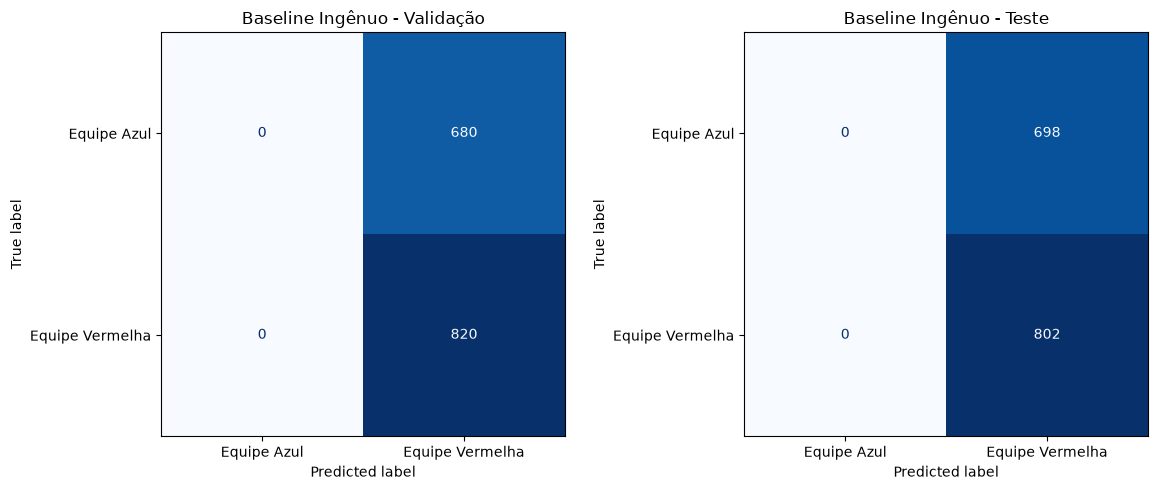

In [10]:
# Criação da figura com dois gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, nome_conjunto, y_real, y_pred in [
    (axes[0], "Validação", y_val, y_val_pred),
    (axes[1], "Teste", y_test, y_test_pred)
]:

    cm = confusion_matrix(y_real, y_pred, labels=[100, 200])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Equipe Azul", "Equipe Vermelha"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"Baseline Ingênuo - {nome_conjunto}")

plt.tight_layout()
plt.show()

In [11]:
cm_teste = confusion_matrix(y_test, y_test_pred, labels=[100, 200])

print("Matriz de confusão — Teste")
print("Linhas: valores reais | Colunas: previsões")
print("Ordem das classes: Equipe Azul (100), Equipe Vermelha (200)")
print(cm_teste)

Matriz de confusão — Teste
Linhas: valores reais | Colunas: previsões
Ordem das classes: Equipe Azul (100), Equipe Vermelha (200)
[[  0 698]
 [  0 802]]
